In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

<Axes: >

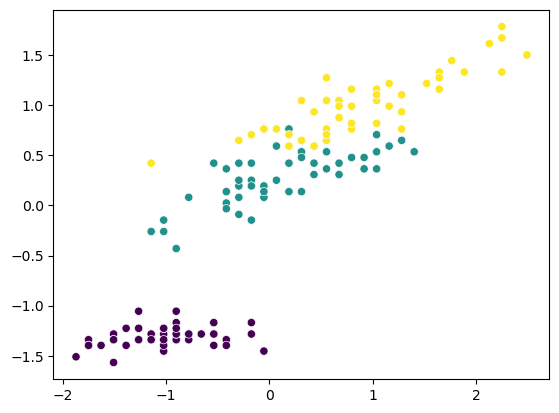

In [4]:
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 2], c=y)

In [5]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

In [6]:
labels = dbscan.fit_predict(X_scaled)

<Axes: >

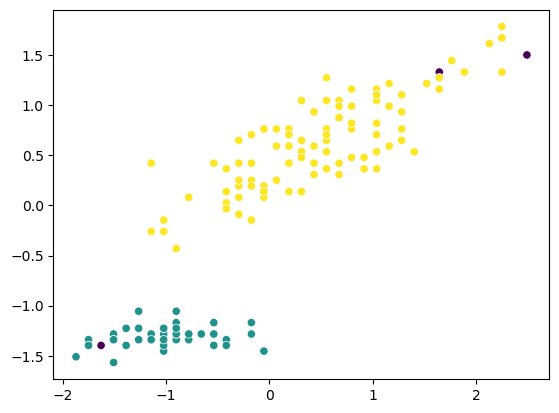

In [7]:
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 2], c=labels)

In [8]:
from sklearn.datasets import make_moons

In [9]:
X , y = make_moons(
    n_samples = 300,
    noise = 0.05,
    # random_state = 42
)

In [10]:
X_scaled = scaler.fit_transform(X)

<Axes: >

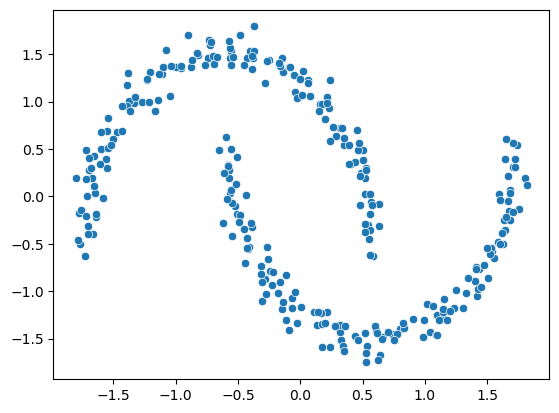

In [11]:
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1])

In [12]:
from sklearn.cluster import KMeans

In [13]:
K = 2
kmeans = KMeans(n_clusters=K, random_state=42)
labels = kmeans.fit_predict(X_scaled)

In [14]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

labels2 = dbscan.fit_predict(X_scaled)

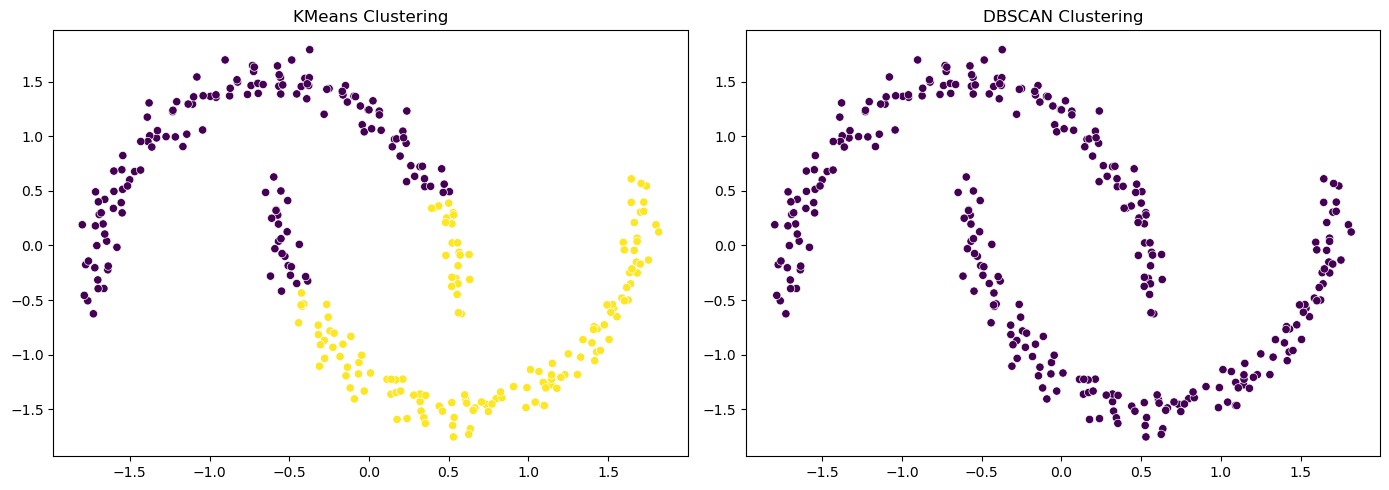

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KMeans
sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    c=labels,
    ax=axes[0]
)
axes[0].set_title("KMeans Clustering")

# DBSCAN
sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    c=labels2,
    ax=axes[1]
)
axes[1].set_title("DBSCAN Clustering")

plt.tight_layout()
plt.show()